# Backtest de los planes: riqueza y UVR

Lee `results/backtest_<plan>.csv` (generados con `python -m uvr_loan.backtest`) y muestra tres paneles que comparten el eje del tiempo:

- **Riqueza:** millones de COP del plan 1 (conservador) y del plan 2 (escalera de CDT optimizada).
- **Liquidez:** saldo del FIC de cada plan al cierre de cada mes (después del pago y, en los meses de revisión, después de repartir), junto con el pago del mes en COP. Los puntos marcan los meses con déficit.
- **UVR:** UVR real y la UVR proyectada en cada revisión **por el plan 1**. Es la que usa su regla para dimensionar el FIC (el plan 2 decide con su propio LP en UVR): parte de la UVR del día de la revisión y crece con la inflación del escenario `liquidity_scenario` calculada en esa revisión (inflación de los últimos `base_lookback_months` meses más el choque) durante los `rebalance_every` meses siguientes.

Se usan paneles separados en lugar de varios ejes Y en un mismo gráfico, porque las escalas y unidades son distintas (COP y COP por UVR).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from uvr_loan.cashflows import decision_months, month_to_period
from uvr_loan.config import RESULTS_DIR, load_assumptions
from uvr_loan.data.cleaning import load_monthly_panel
from uvr_loan.inflation import project_uvr, scenarios

cfg = load_assumptions()
bt = cfg["backtest"]
k = bt["rebalance_every"]
scenario = cfg["conservative"]["liquidity_scenario"]
panel = load_monthly_panel(cfg)  # UVR history before each review

PLANS = {"conservative": "Plan 1 – conservador", "cdt_ladder": "Plan 2 – escalera de CDT"}
results = {}
for plan in PLANS:
    df = pd.read_csv(RESULTS_DIR / f"backtest_{plan}.csv")
    df["date"] = pd.PeriodIndex(df["period"], freq="M").to_timestamp(how="end").normalize()
    results[plan] = df
dates = results["conservative"]["date"]
results["cdt_ladder"].head()

8 fund-days excluded from the FIC index: unit value <= 0


  fund 9-76762-501 on 2018-10-06: unit value 10146.403131 -> 0.0 (-100.00%)


  fund 9-76762-501 on 2018-10-07: unit value 0.0 -> 0.0 (+nan%)


  fund 9-76762-501 on 2018-10-08: unit value 0.0 -> 0.0 (+nan%)


  fund 9-76762-501 on 2018-10-09: unit value 0.0 -> 0.0 (+nan%)


  fund 14-58564-601 on 2020-03-07: unit value 12366.002619 -> 0.0 (-100.00%)


... (6 outputs left out)

  fund 12-11407-522 on 2025-02-27: unit value 11979.230459 -> 10000.0 (-16.52%)


  fund 58-16373-800 on 2021-06-21: unit value 13617.599372 -> 12889.090546 (-5.35%)


  fund 58-16373-800 on 2021-06-23: unit value 12888.56474 -> 13605.302101 (+5.56%)


,month,period,uvr,payment_cop,shortfall,fic,cdt,etf,wealth,review,date
0,0,2016-10,242.5180,0.0,0.0,0.0,7.600000e+08,0.0,7.600000e+08,True,2016-10-31
1,1,2016-11,242.3866,0.0,0.0,0.0,7.648757e+08,0.0,7.648757e+08,False,2016-11-30
2,2,2016-12,242.4513,0.0,0.0,0.0,7.697827e+08,0.0,7.697827e+08,False,2016-12-31
3,3,2017-01,243.1056,0.0,0.0,0.0,7.747212e+08,0.0,7.747212e+08,False,2017-01-31
4,4,2017-02,244.7496,0.0,0.0,0.0,7.796915e+08,0.0,7.796915e+08,False,2017-02-28


## UVR proyectada en cada revisión (plan 1)

Un tramo por revisión τ: los meses τ … τ + k, empezando en la UVR real de τ.

In [2]:
uvr_real = results["conservative"].set_index("month")["uvr"]


def projection(tau: int) -> pd.Series:
    months = range(tau, tau + k + 1)
    inflation = scenarios(cfg, panel.loc[: month_to_period(bt["t0"], tau), "uvr"])[scenario]
    values = [uvr_real[tau], *project_uvr(uvr_real[tau], inflation, k)]
    dates = [month_to_period(bt["t0"], m).to_timestamp(how="end").normalize() for m in months]
    return pd.Series(values, index=dates)


projections = [projection(tau) for tau in decision_months(bt)]

## Gráfico

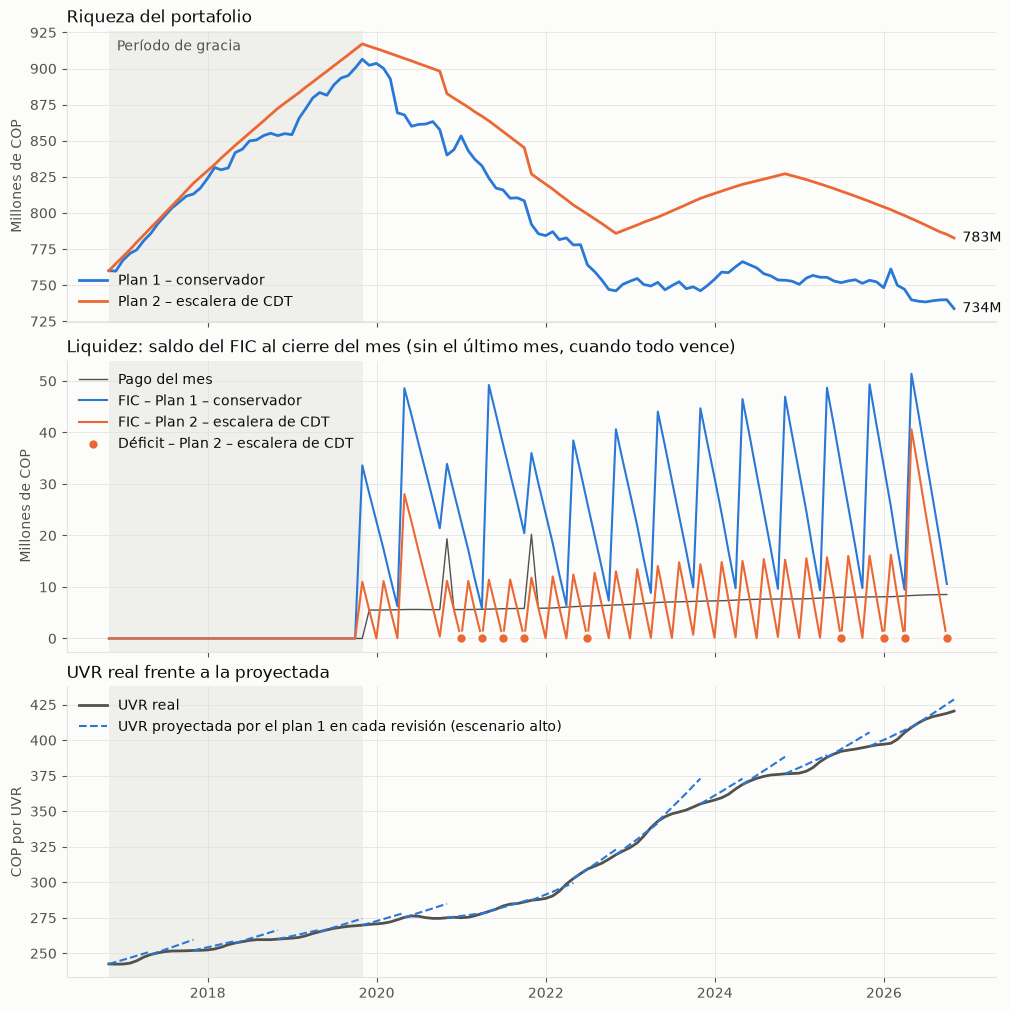

In [3]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
COLORS = {"conservative": BLUE, "cdt_ladder": ORANGE}  # one color per plan, in both panels
SCENARIO_NAMES = {"base": "base", "high": "alto", "low": "bajo"}
TEXT, TEXT_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": TEXT_2,
        "axes.titlecolor": TEXT,
        "xtick.color": TEXT_2,
        "ytick.color": TEXT_2,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "font.size": 10,
    }
)

grace_end = month_to_period(bt["t0"], cfg["loan"]["grace_months"]).to_timestamp(how="end")
fig, (ax_w, ax_l, ax_u) = plt.subplots(3, 1, sharex=True, figsize=(10, 10), constrained_layout=True)

for ax in (ax_w, ax_l, ax_u):
    ax.axvspan(dates.iloc[0], grace_end, color=GRID, alpha=0.5, lw=0)
ax_w.text(
    dates.iloc[0], 0.97, "  Período de gracia", transform=ax_w.get_xaxis_transform(), va="top", color=TEXT_2
)

# Riqueza de cada plan
for plan, df in results.items():
    ax_w.plot(df["date"], df["wealth"] / 1e6, color=COLORS[plan], lw=2, label=PLANS[plan])
    last = df.iloc[-1]
    ax_w.annotate(
        f"{last['wealth'] / 1e6:,.0f}M",
        (last["date"], last["wealth"] / 1e6),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color=TEXT,
    )
ax_w.set_title("Riqueza del portafolio", loc="left")
ax_w.set_ylabel("Millones de COP")
ax_w.legend(frameon=False, loc="lower left", labelcolor=TEXT)

# Liquidez: saldo del FIC de cada plan y pago del mes (neutral: es el mismo para los dos planes).
# Sin el último mes: en el mes H vencen todos los CDT y la escala no dejaría ver el resto.
last_month = bt["horizon_months"]
payments = results["conservative"].query("month < @last_month")
ax_l.plot(payments["date"], payments["payment_cop"] / 1e6, color=TEXT_2, lw=1, label="Pago del mes")
for plan, df in results.items():
    df = df[df["month"] < last_month]
    ax_l.plot(df["date"], df["fic"] / 1e6, color=COLORS[plan], lw=1.5, label=f"FIC – {PLANS[plan]}")
    short = df[df["shortfall"] > 0]
    ax_l.scatter(
        short["date"],
        short["fic"] / 1e6,
        s=64,
        color=COLORS[plan],
        edgecolor=SURFACE,
        linewidth=2,
        zorder=3,
        label=f"Déficit – {PLANS[plan]}" if len(short) else None,
    )
ax_l.set_title("Liquidez: saldo del FIC al cierre del mes (sin el último mes, cuando todo vence)", loc="left")
ax_l.set_ylabel("Millones de COP")
ax_l.legend(frameon=False, loc="upper left", labelcolor=TEXT)

# UVR real (neutral: no pertenece a ningún plan) y proyectada por el plan 1
ax_u.plot(dates, uvr_real.values, color=TEXT_2, lw=2, label="UVR real")
for i, p in enumerate(projections):
    label = (
        f"UVR proyectada por el plan 1 en cada revisión (escenario {SCENARIO_NAMES[scenario]})"
        if i == 0
        else None
    )
    ax_u.plot(p.index, p.values, color=COLORS["conservative"], lw=1.5, ls="--", label=label)
ax_u.set_title("UVR real frente a la proyectada", loc="left")
ax_u.set_ylabel("COP por UVR")
ax_u.legend(frameon=False, loc="upper left", labelcolor=TEXT)

plt.show()